# Myers Bit-Vector Edit Distance

Represent one dynamic-programming column with bits and update many pattern positions using integer operations.

The objective is global unit-cost edit distance. A mismatch, insertion or deletion costs one. The high bit tracks the change of the final row. Python integers can hold longer patterns than a machine word, with work proportional to the number of underlying words.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from genome_methods import bit_distance, rng_dna
import edlib

## Worked example

Run the example from top to bottom. The printed check and figure use the same observations.

Global edit distances [0, 2, 6, 10, 15, 23]


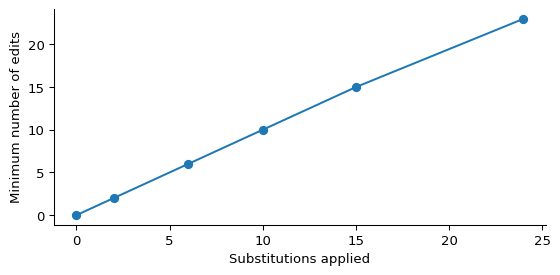

In [2]:
rng = np.random.default_rng(17)
a = rng_dna(rng, 96)
cost = []
for n in [0, 2, 6, 10, 15, 24]:
    b = list(a)
    for j in rng.choice(len(a), n, replace=False):
        b[j] = next(c for c in "ACGT" if c != b[j])
    b = "".join(b)
    d = bit_distance(a, b)
    assert d == edlib.align(a, b, mode="NW")["editDistance"]
    cost.append(d)
assert bit_distance("", "ACT") == 3
print("Global edit distances", cost)
plt.figure(figsize=(6, 3))
plt.plot([0, 2, 6, 10, 15, 24], cost, "o-")
plt.xlabel("Substitutions applied")
plt.ylabel("Minimum number of edits")
plt.tight_layout()
plt.show()

## Interpreting the result

The edit distance can be lower than the number of changes applied because a different sequence of edits can reach the same string.

## Exercise

Insert a two-base run instead of substituting bases and verify the answer with Edlib.

## References

[Myers, bit-vector approximate string matching (1999)](https://doi.org/10.1145/316542.316550)

[Šošić and Šikić, Edlib (2017)](https://doi.org/10.1093/bioinformatics/btw753)